
# Lab 9: Quantun Computing - Rabi Oscillations

Nombre estudiante:

c.c:

## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule 

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.
 
 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

## Exercise: Bell state

1. Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a `Bell state`  (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

2. Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

3. See your results shift by adding qc.x(1) to the end of the circuit.

In [1]:
#Librery
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

# Solución

## Ejercicio 1

Para resolver el ejercicio usamos lo que se vio en clase del sistema de dos niveles. Ahí tenemos que

$$\Omega=\sqrt{\Omega_R^2+\Delta^2}$$

donde $\Omega_R$ es la frecuencia de Rabi, $\Delta$ es el detuning y $\Omega$ es la frecuencia de Rabi generalizada.

En este caso el detuning es $\Delta=\Omega_R/2$, entonces reemplazando:

$$\Omega^2=\Omega_R^2+\frac{\Omega_R^2}{4}=\frac{5}{4}\Omega_R^2$$

$$\Omega_R=\frac{2}{\sqrt{5}}\Omega$$

Como el estado inicial es $\ket{2}$ y no $\ket{1}$, ahora nos interesa $U_{22}(t)$. Con la $U(t)$ de clase:

$$U_{22}(t)=\cos(\Omega t)+i\sin(\Omega t)\frac{c_z}{|c|}$$

que es igual a $U_{11}$ pero con el signo cambiado en la parte imaginaria, entonces al sacar el módulo al cuadrado queda la misma forma de $P_1(t)$:

$$P_2(t)=\cos^2(\Omega t)+\sin^2(\Omega t)\frac{\Delta^2}{\Omega^2}$$

y la probabilidad de pasar al estado $\ket{1}$ es $P_1(t)=1-P_2(t)$.

In [2]:
# Rutina de clase
hbar = 1.0545718e-34 # Planck's constant over 2 pi in J*s
#Rabi frequency:
def Omega_Rabi(cx,cy):
    return np.sqrt(cx**2 + cy**2)/hbar
#Detuning:
def Delta(cz):
    return np.abs(cz)/hbar
#Generalized Rabi frequency:
def Omega(cx,cy,cz):
    return np.sqrt(Omega_Rabi(cx,cy)**2 + Delta(cz)**2)
#Probability of being in state |1> at time t:
def P1(cx,cy,cz,t):
    return np.cos(Omega(cx,cy,cz)*t)**2 + np.sin(Omega(cx,cy,cz)*t)**2*(Delta(cz)/Omega(cx,cy,cz))**2

### Punto 1

In [3]:
# Inciso punto 1
f = 24.79e9  # Omega/2pi en Hz
Omega_NH3 = 2*np.pi*f

Omega_R = 2*Omega_NH3/np.sqrt(5)
Delta_NH3 = Omega_R/2

print(f"Detuning: {Delta_NH3/(2*np.pi):.3e} Hz")

Detuning: 1.109e+10 Hz


### Punto 2

Rabi frequency: 2.217e+10 Hz
Detuning: 1.109e+10 Hz
Generalized Rabi frequency: 2.479e+10 Hz


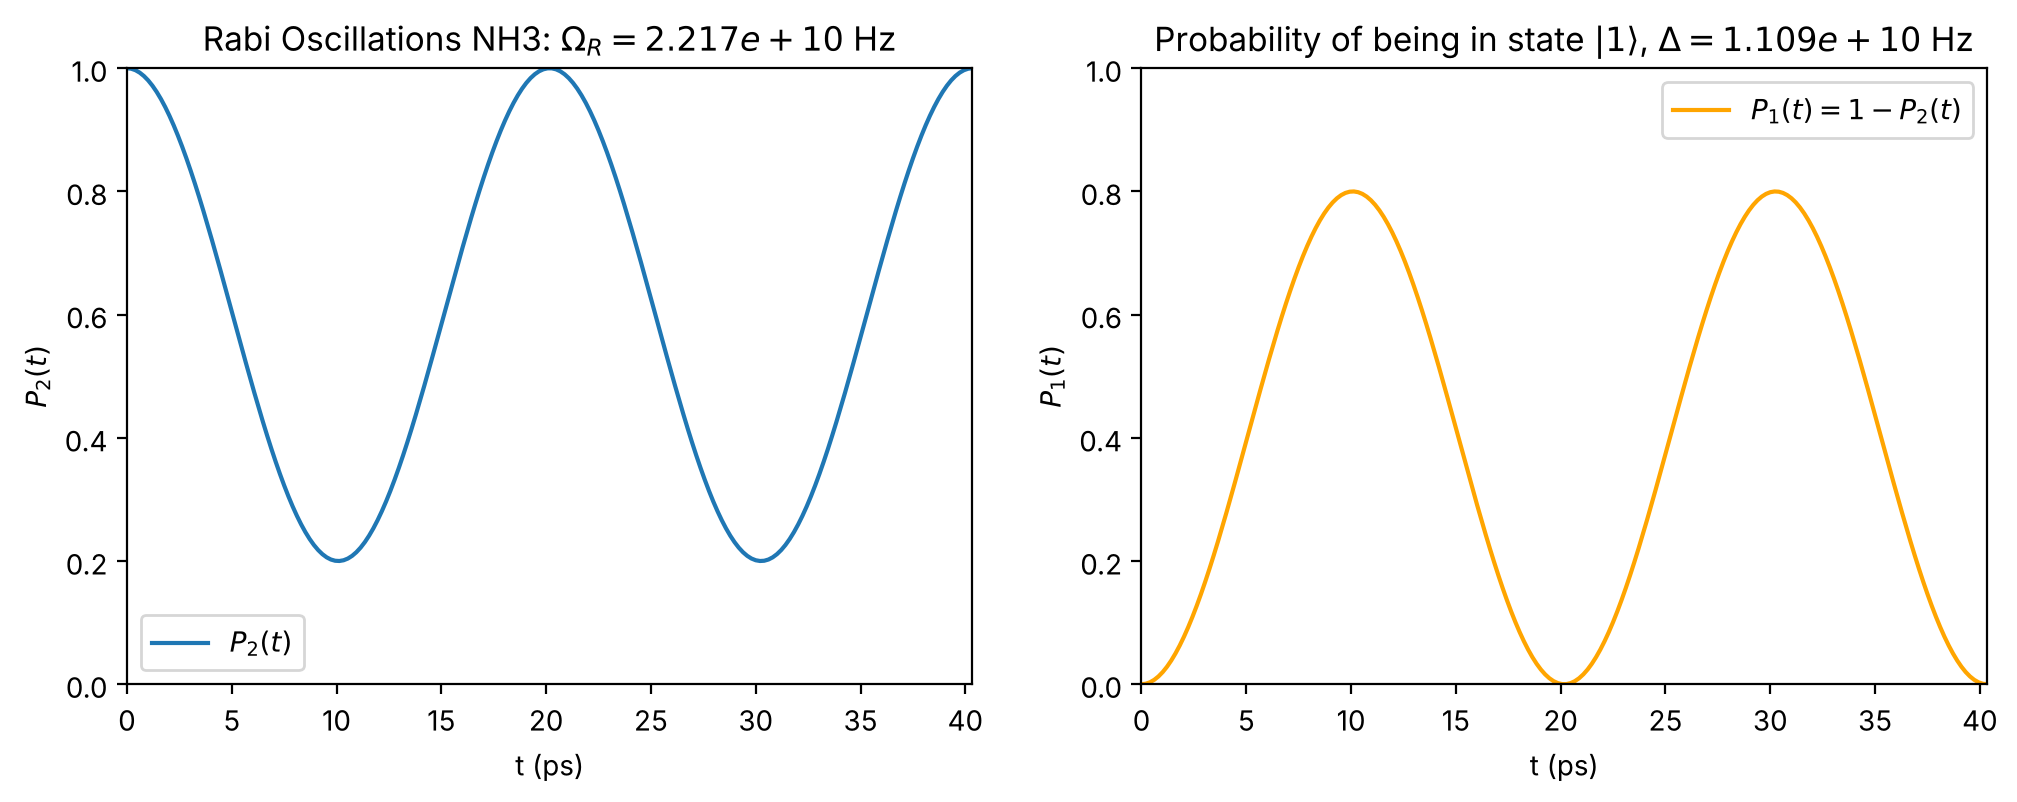

In [4]:
# Inciso punto 2

plt.figure(figsize=(12, 4))
cx = hbar*Omega_R
cy = 0
cz = hbar*Delta_NH3

print(f"Rabi frequency: {Omega_Rabi(cx,cy)/(2*np.pi):.3e} Hz")
print(f"Detuning: {Delta(cz)/(2*np.pi):.3e} Hz")
print(f"Generalized Rabi frequency: {Omega(cx,cy,cz)/(2*np.pi):.3e} Hz")
t = np.linspace(0, 2*np.pi/Omega(cx,cy,cz), 200)
Pr = P1(cx,cy,cz,t)

###################### P2 ###############
plt.subplot(1, 2, 1)
plt.plot(t*1e12, Pr, label='$P_2(t)$')
plt.xlabel('t (ps)')
plt.ylabel('$P_2(t)$')
plt.xlim(t.min()*1e12, t.max()*1e12)
plt.ylim(0, 1)
plt.title(f'Rabi Oscillations NH3: $\\Omega_R={Omega_Rabi(cx,cy)/(2*np.pi):.3e}$ Hz')
plt.legend()

###################### P1 ###############
plt.subplot(1, 2, 2)
plt.plot(t*1e12, 1 - Pr, color='orange', label='$P_1(t)=1-P_2(t)$')
plt.xlabel('t (ps)')
plt.ylabel('$P_1(t)$')
plt.xlim(t.min()*1e12, t.max()*1e12)
plt.ylim(0, 1)
plt.title(f'Probability of being in state $|1\\rangle$, $\\Delta={Delta(cz)/(2*np.pi):.3e}$ Hz')
plt.legend()
plt.show()

**Justificación:** Usé las mismas funciones de clase (`Omega_Rabi`, `Delta`, `Omega` y `P1`). Primero despejé $\Omega_R$ de $\Omega^2=\Omega_R^2+\Delta^2$ con $\Delta=\Omega_R/2$. Después pasé las frecuencias a los coeficientes del hamiltoniano con $c_x=\hbar\Omega_R$, $c_y=0$ y $c_z=\hbar\Delta$, para poder meterlos en las funciones. Como el estado inicial es $\ket{2}$, la función `P1` de clase me da la probabilidad de seguir en $\ket{2}$, y la de pasar a $\ket{1}$ es $1-P_2$. Tomé $\Omega/2\pi=24.79$ GHz como dice el enunciado.

**Conclusión:** La frecuencia de Rabi del NH3 es de $22.17$ GHz y el detuning de $11.09$ GHz. La molécula oscila entre los dos estados con un periodo de más o menos $20$ ps. Por el detuning no pasa completamente al estado $\ket{1}$, la probabilidad máxima de llegar a $\ket{1}$ es $\Omega_R^2/\Omega^2=4/5$ y $P_2$ nunca baja de $0.2$.

## Ejercicio 2

Usamos lo que se vio en clase de qiskit. El estado de Bell se construye con una compuerta Hadamard en el qubit 0 y después una CNOT con control en el qubit 0 y objetivo en el qubit 1:

$$\ket{00}\xrightarrow{H}\frac{\ket{00}+\ket{01}}{\sqrt{2}}\xrightarrow{CNOT}\frac{\ket{00}+\ket{11}}{\sqrt{2}}$$

Para simular usamos el `qasm_simulator` de Aer como en clase. Como lo vamos a usar varias veces lo pusimos en una función.

In [5]:
# Rutina de clase
backend = Aer.get_backend('qasm_simulator') # locally

def simular(qc, shots=1000):
    compiled_circuit = transpile(qc, backend)
    job = backend.run(compiled_circuit, shots=shots)
    result_sim = job.result()
    return result_sim.get_counts(qc)

### Punto 1

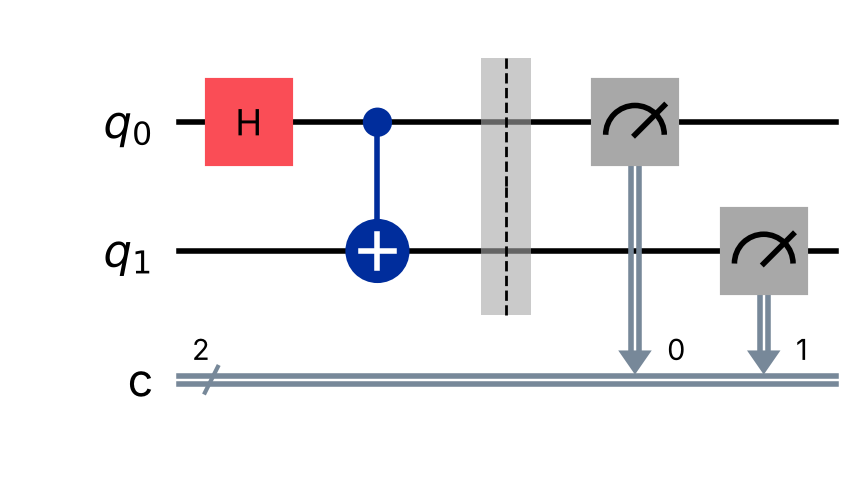

In [6]:
# Inciso punto 1
q_bell = QuantumCircuit(2,2)
q_bell.h(0)
q_bell.cx(0,1)
q_bell.barrier()
q_bell.measure([0,1],[0,1])

q_bell.draw(output='mpl',plot_barriers=True)

{'00': 482, '11': 518}


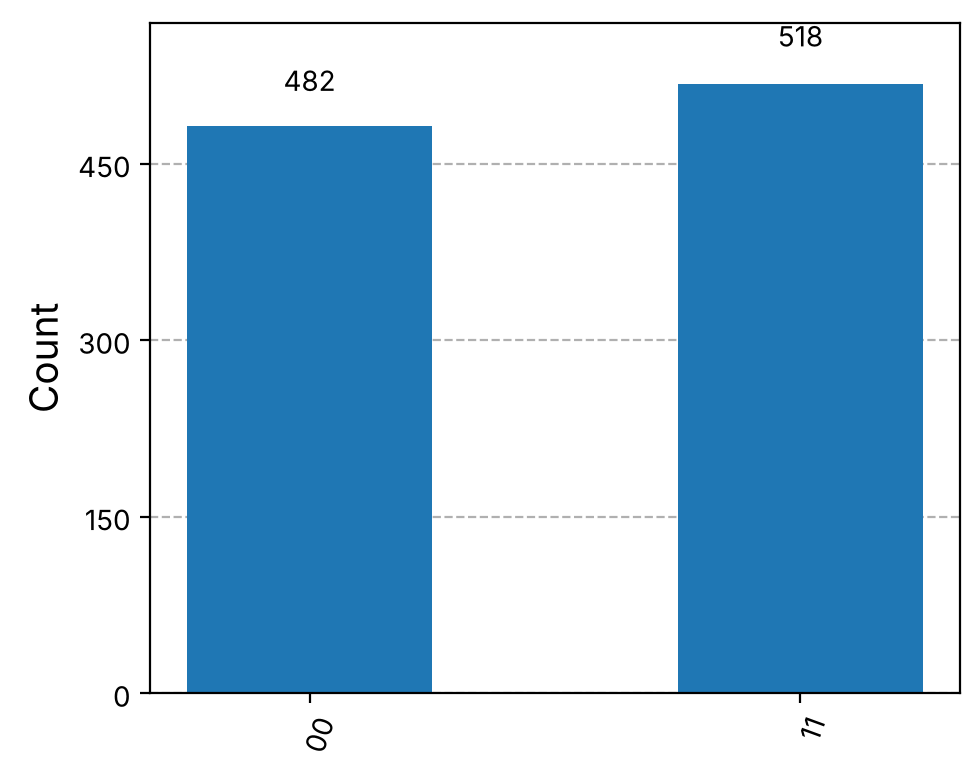

In [7]:
counts_bell = simular(q_bell)
print(counts_bell)
plot_histogram(counts_bell,figsize=(5,4))

### Punto 2

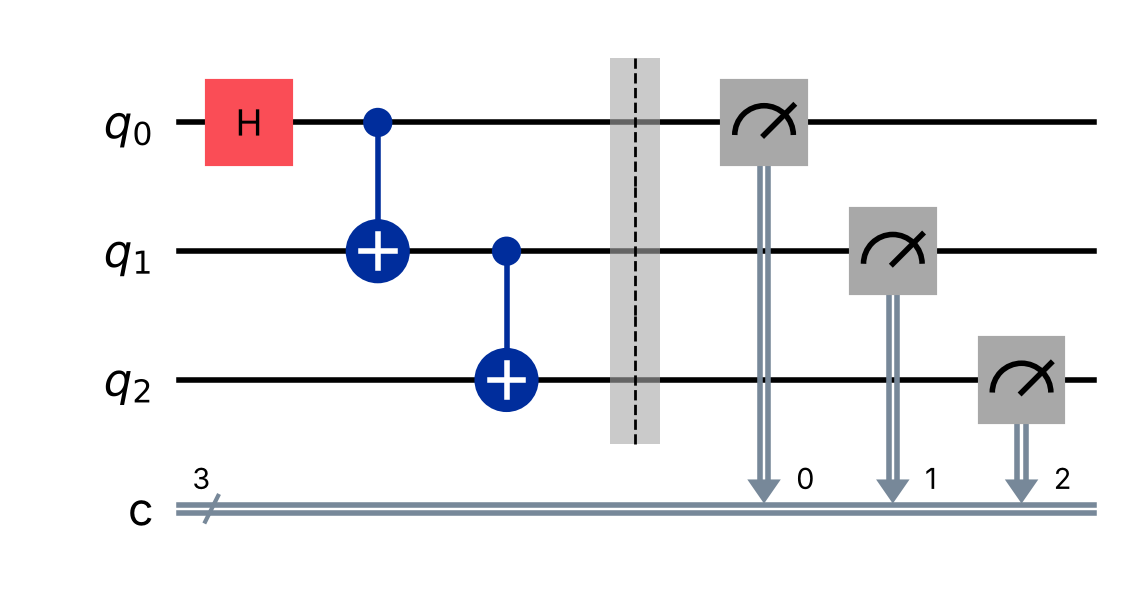

In [8]:
# Inciso punto 2
qc = QuantumCircuit(3,3)
qc.h(0)
qc.cx(0,1)
qc.cx(1,2)
qc.barrier()
qc.measure([0,1,2],[0,1,2])

qc.draw(output='mpl',plot_barriers=True)

{'111': 531, '000': 469}


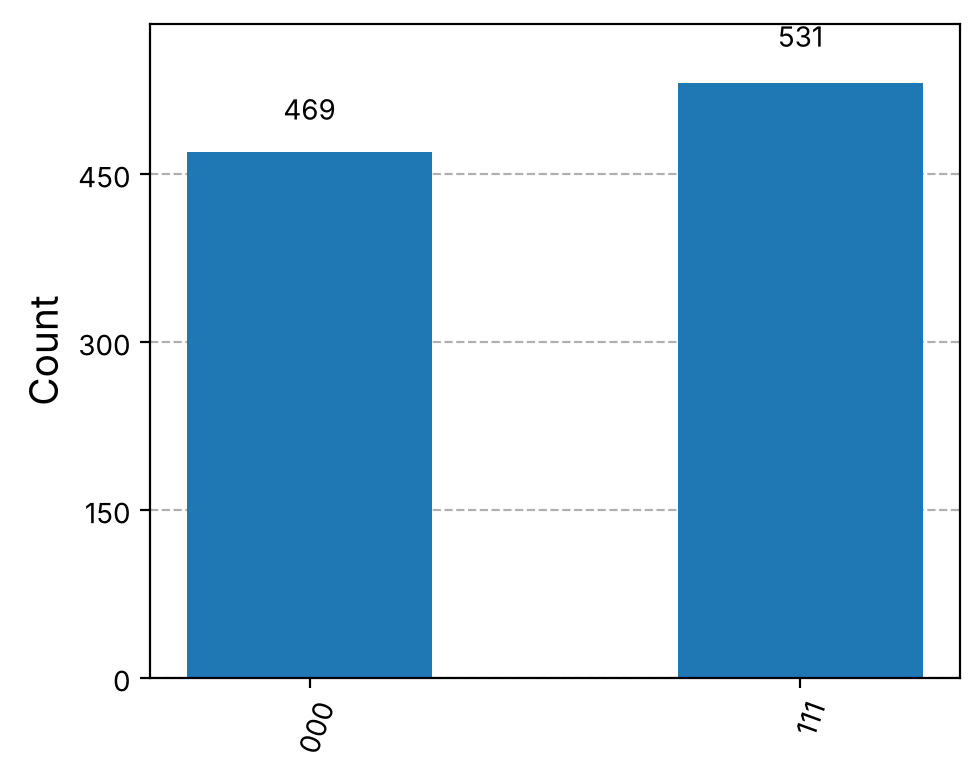

In [9]:
counts_3 = simular(qc)
print(counts_3)
plot_histogram(counts_3,figsize=(5,4))

### Punto 3

Primero lo ponemos al final del circuito, después de medir.

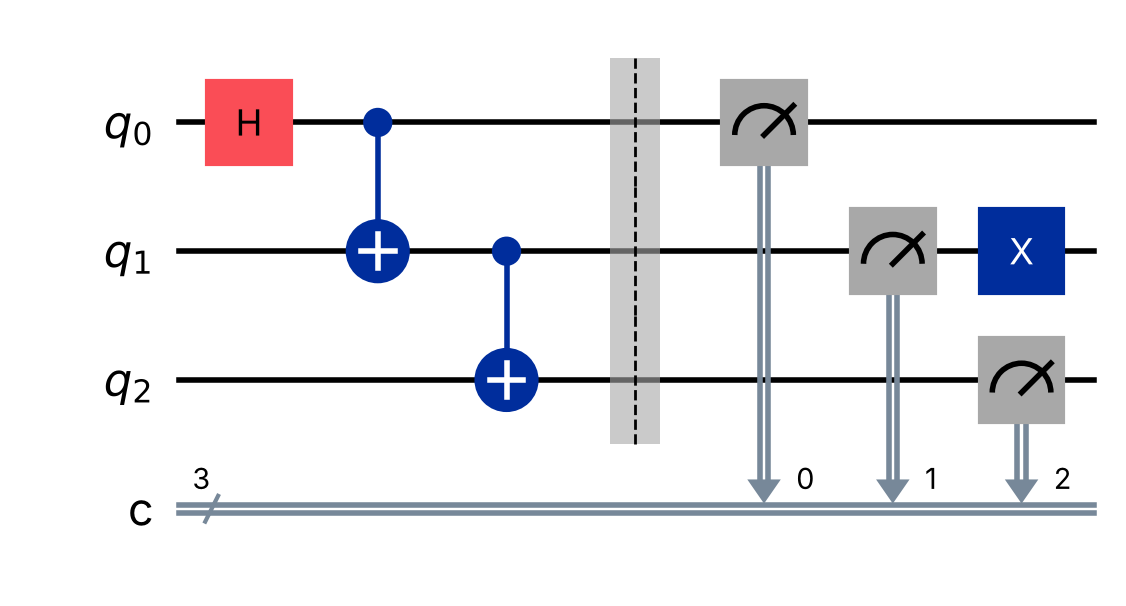

{'000': 507, '111': 493}


In [10]:
# Inciso punto 3
qc_a = qc.copy()
qc_a.x(1)

display(qc_a.draw(output='mpl',plot_barriers=True))
counts_a = simular(qc_a)
print(counts_a)

Los resultados no cambian. Entonces probamos poniendo `qc.x(1)` al final de las compuertas pero antes de medir.

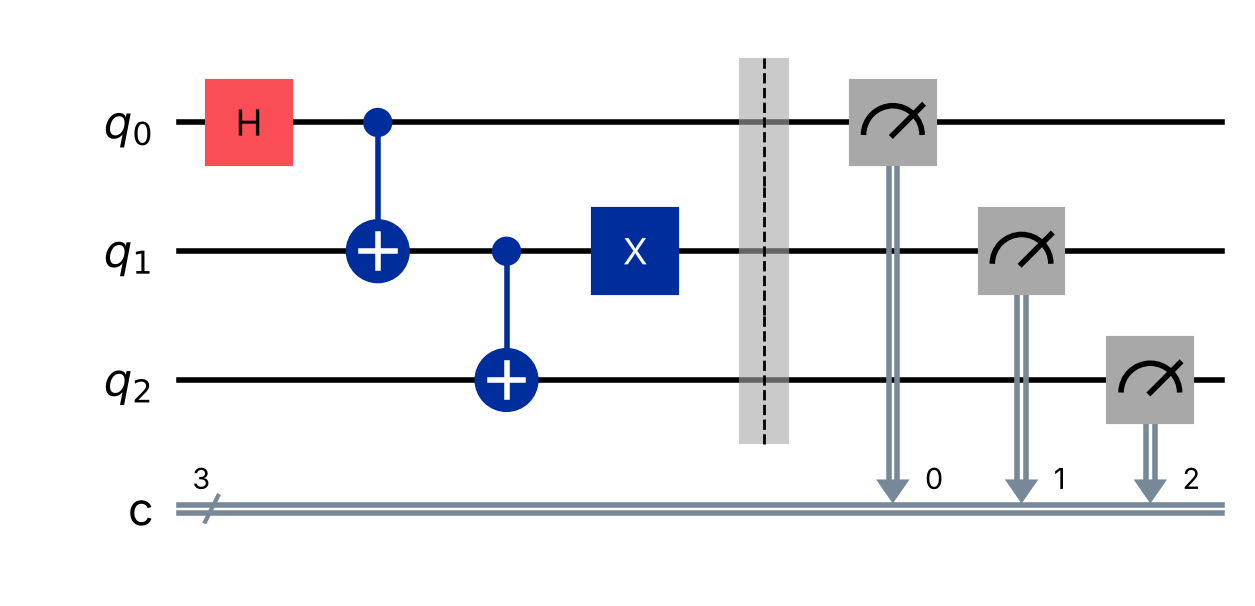

{'010': 517, '101': 483}


In [11]:
qc_b = QuantumCircuit(3,3)
qc_b.h(0)
qc_b.cx(0,1)
qc_b.cx(1,2)
qc_b.x(1)
qc_b.barrier()
qc_b.measure([0,1,2],[0,1,2])

display(qc_b.draw(output='mpl',plot_barriers=True))
counts_b = simular(qc_b)
print(counts_b)

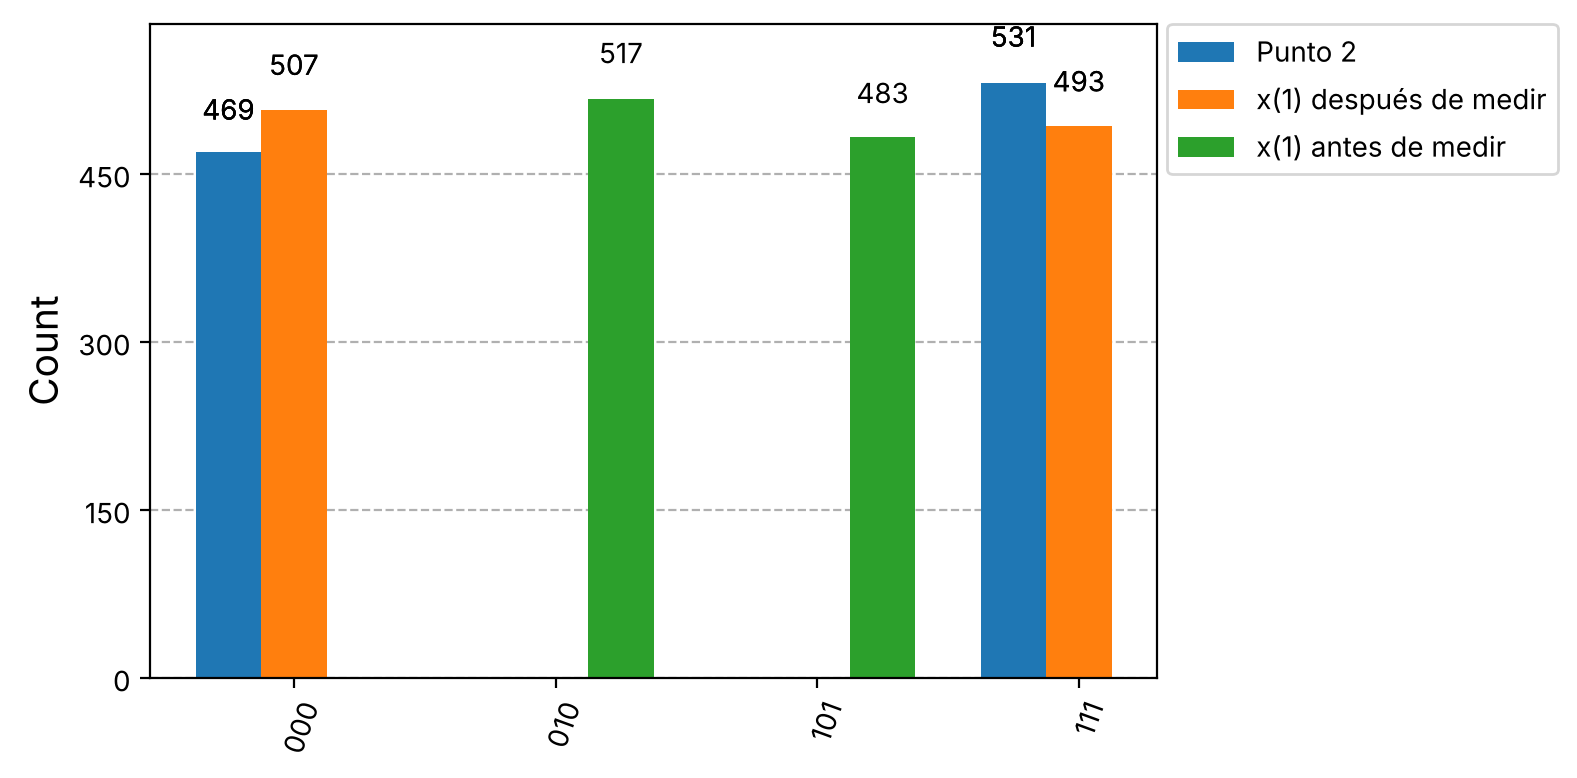

In [12]:
plot_histogram([counts_3, counts_a, counts_b], legend=['Punto 2', 'x(1) después de medir', 'x(1) antes de medir'], figsize=(8,4))

**Justificación:** Usé los mismos pasos de clase para simular (backend, transpile y run) y los metí en la función `simular`. En el punto 1 salen solo `00` y `11` más o menos la mitad de las veces cada uno, porque el estado es $\frac{\ket{00}+\ket{11}}{\sqrt{2}}$. En el punto 2 la segunda CNOT copia el qubit 1 en el qubit 2, entonces el estado queda $\frac{\ket{000}+\ket{111}}{\sqrt{2}}$ y solo salen `000` y `111`. En el punto 3, si `x(1)` va después de medir no cambia nada porque los bits clásicos ya se guardaron. Si va antes de medir, la compuerta X es como un NOT y voltea el qubit 1, entonces el estado queda $\frac{\ket{010}+\ket{101}}{\sqrt{2}}$. Qiskit escribe los bits al revés (el qubit 0 a la derecha), pero como el qubit 1 es el del medio da igual.

**Conclusión:** Con la Hadamard y la CNOT se obtiene el estado de Bell, los dos qubits quedan entrelazados porque si uno da 0 el otro también y si uno da 1 el otro también. Con un tercer qubit y otra CNOT los tres quedan entrelazados (`000` y `111`). Al agregar `x(1)` antes de medir los resultados cambian a `010` y `101`, pero si se agrega después de medir no pasa nada.